# Cours 1 — Nettoyage, qualité et statistiques (7 jeux ERP)

**M2 Data Science · Data Mining · Travail de groupe · Domaine logistique**

Sept fichiers ERP sources : partenaires, installations, bons de réception, mouvements correctifs, inventaire mensuel, **lignes de commandes d’achat**, **expéditions**. Les calculs utilisent exclusivement les données ERP ; tous les signaux sont des *hypothèses à vérifier*, jamais des preuves de fraude.

## 1. Audit initial et questions métier

Le cours 1 insiste sur les doublons, formats, valeurs manquantes et valeurs aberrantes (pages 3–10), puis les distributions et corrélations. On **conserve les transactions suspectes** et on journalise les corrections : une valeur extrême peut représenter un événement important.

**Chaîne ERP** : partenaire → commande (`purchase_order_number` + `purchase_order_line`) → réception ; expédition (`shipment_number`) avec expéditeur, destinataire, transporteur et sites ; ajustement pouvant référencer réception ou expédition ; état de stock mensuel.

Les unités (`case`, `kit`, `sealed_lot`, `service`, etc.) ne s'additionnent **jamais** sans conversion documentée.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT=Path.cwd()
if not (ROOT/'data/raw').exists(): ROOT=ROOT.parent
assert (ROOT/'data/raw').exists(), "Ouvrir le notebook depuis la racine du dépôt ou son répertoire notebooks/"
SEED=42
pd.set_option('display.max_columns',35)
pd.set_option('display.max_colwidth',85)
NAMES=['erp_business_partners','erp_facilities','goods_receipts','inventory_adjustments','inventory_month_end','purchase_order_lines','shipments']
RAW=ROOT/'data/raw';OUT=ROOT/'data/part1_clean';OUT.mkdir(parents=True,exist_ok=True)
raw={k:pd.read_csv(RAW/f'{k}.csv',dtype=str) for k in NAMES}
audit=pd.DataFrame([{'source_dataset':k,'raw_rows':len(v),'columns':len(v.columns),'exact_duplicates':int(v.duplicated().sum()),'missing_cells':int(v.isna().sum().sum())} for k,v in raw.items()]);display(audit)
audit.to_csv(OUT/'dataset_quality_summary.csv',index=False)
assert len(raw)==7


,source_dataset,raw_rows,columns,exact_duplicates,missing_cells
0,erp_business_partners,80,11,0,15
1,erp_facilities,30,11,0,1
2,goods_receipts,612,12,2,4
3,inventory_adjustments,140,11,0,221
4,inventory_month_end,502,11,2,0
5,purchase_order_lines,651,16,1,3
6,shipments,452,16,2,17


## 2. Audit colonne par colonne

On distingue les valeurs réellement absentes et les valeurs mal converties. Ne pas imputer automatiquement les numéros d'immatriculation, les numéros de commande et les numéros d'expédition : cela créerait de faux liens inter-domaines.

In [2]:
quality=pd.concat([pd.DataFrame([{'source_dataset':name,'column':col,'missing_n':int(d[col].isna().sum()),'missing_pct':round(d[col].isna().mean()*100,2),'distinct_values':d[col].nunique(dropna=True)} for col in d]) for name,d in raw.items()],ignore_index=True)
quality.to_csv(OUT/'quality_audit.csv',index=False)
display(quality.sort_values('missing_pct',ascending=False).head(18))


,source_dataset,column,missing_n,missing_pct,distinct_values
42,inventory_adjustments,related_receipt_number,117,83.57,23
43,inventory_adjustments,related_shipment_number,103,73.57,37
3,erp_business_partners,external_registration_number,14,17.50,66
75,shipments,arrival_time,17,3.76,425
21,erp_facilities,storage_capabilities,1,3.33,4
4,erp_business_partners,billing_region,1,1.25,5
41,inventory_adjustments,approved_by_role,1,0.71,7
31,goods_receipts,inspection_status,4,0.65,3
70,purchase_order_lines,declared_cost_center,3,0.46,9
8,erp_business_partners,partner_status,0,0.00,2


## 3. Nettoyage non destructif

- Suppression **uniquement** des doublons de lignes entièrement identiques ; préservation des identifiants métier distincts.
- `strip`, espaces multiples normalisés, harmonisation contrôlée des **catégories** et statuts (y compris les températures `2-8C`). Les noms et descriptions restent en casse d'origine.
- Dates ISO sans fabrication de dates ; colonnes monétaires/quantitatives converties en numérique ; création d'un audit pour les erreurs de parsing.
- Conservation du signe des quantités négatives et des valeurs extrêmes. Le jeu brut reste intact.

In [3]:
from collections import defaultdict
DATE={
 'erp_business_partners':['onboarding_date'],'erp_facilities':['opening_date'],
 'goods_receipts':['receipt_date'],'inventory_adjustments':['adjustment_date'],
 'inventory_month_end':['reporting_month'],
 'purchase_order_lines':['order_date','requested_delivery_date'],
 'shipments':['dispatch_time','arrival_time']}
NUM={
 'erp_business_partners':[],'erp_facilities':['latitude','longitude'],
 'goods_receipts':['purchase_order_line','received_quantity'],
 'inventory_adjustments':['adjustment_quantity'],
 'inventory_month_end':['opening_stock','received_quantity','outgoing_quantity','documented_internal_use','documented_waste','closing_stock'],
 'purchase_order_lines':['purchase_order_line','ordered_quantity','unit_price'],
 'shipments':['shipment_leg','declared_quantity']}
CATEG={
 'erp_business_partners':['partner_role','partner_status','risk_class','payment_terms'],
 'erp_facilities':['facility_category','facility_status'],
 'goods_receipts':['received_unit','inspection_status','receipt_status'],
 'inventory_adjustments':['item_category','unit','adjustment_reason','approved_by_role','adjustment_status'],
 'inventory_month_end':['item_category','unit','inventory_status'],
 'purchase_order_lines':['item_category','ordered_unit','currency','authorization_class','declared_cost_center','order_status'],
 'shipments':['item_category','declared_unit','temperature_control_class','authorization_class','declared_purpose','shipment_status']}
clean={}; parse=[]
for name,d in raw.items():
 t=d.drop_duplicates().copy()
 for col in t.columns:
  t[col]=t[col].str.strip().replace('',np.nan)
 for col in CATEG[name]:
  t[col]=t[col].str.replace(r'\s+',' ',regex=True).str.lower()
 for col in DATE[name]:
  previous=t[col].copy();parsed=pd.to_datetime(previous,errors='coerce',format='mixed')
  parse.append({'source_dataset':name,'column':col,'kind':'date','invalid_n':int((previous.notna() & parsed.isna()).sum())})
  t[col]=parsed.dt.strftime('%Y-%m-%dT%H:%M:%S') if name=='shipments' else parsed.dt.strftime('%Y-%m-%d')
 for col in NUM[name]:
  previous=t[col].copy();t[col]=pd.to_numeric(t[col].str.replace(',','.',regex=False),errors='coerce')
  parse.append({'source_dataset':name,'column':col,'kind':'number','invalid_n':int((previous.notna() & t[col].isna()).sum())})
 clean[name]=t
 t.to_csv(OUT/f'{name}_clean.csv',index=False)
pd.DataFrame(parse).to_csv(OUT/'parsing_audit.csv',index=False)
audit['clean_rows']=audit.source_dataset.map({k:len(v) for k,v in clean.items()})
audit['removed_duplicates']=audit.raw_rows-audit.clean_rows
assert len(clean)==7
display(audit[['source_dataset','raw_rows','clean_rows','removed_duplicates']])


,source_dataset,raw_rows,clean_rows,removed_duplicates
0,erp_business_partners,80,80,0
1,erp_facilities,30,30,0
2,goods_receipts,612,610,2
3,inventory_adjustments,140,140,0
4,inventory_month_end,502,500,2
5,purchase_order_lines,651,650,1
6,shipments,452,450,2


## 4. Intégrité référentielle : commande ↔ réception ↔ expédition ↔ ajustement

Le point important ajouté grâce aux **deux nouveaux fichiers** : une réception peut être reliée exactement à une ligne de commande par la clé composite `(purchase_order_number, purchase_order_line)`, et une correction d'inventaire à une expédition par `related_shipment_number`. Une référence manquante/étrangère est un **signal de revue**, pas la preuve d'une transaction fictive.

Une expédition peut comporter plusieurs lignes/legs : on vérifie donc l'unicité des identifiants à la granularité appropriée.

In [4]:
bp=clean['erp_business_partners'];fc=clean['erp_facilities'];gr=clean['goods_receipts'];ad=clean['inventory_adjustments'];mo=clean['inventory_month_end'];po=clean['purchase_order_lines'];sh=clean['shipments']
keys_po=po[['purchase_order_number','purchase_order_line']].drop_duplicates()
po_dup=po.duplicated(['purchase_order_number','purchase_order_line']).sum()
ship_dup=sh.duplicated(['shipment_number','shipment_leg']).sum()
rc_check=gr.merge(keys_po.assign(found_po=1),on=['purchase_order_number','purchase_order_line'],how='left')
partner_ids=set(bp.partner_code.dropna());facility_ids=set(fc.facility_code.dropna());ship_ids=set(sh.shipment_number.dropna());receipt_ids=set(gr.receipt_number.dropna())
checks={
 'Commande : clé (PO,line) dupliquée':int(po_dup),
 'Expédition : clé (shipment,leg) dupliquée':int(ship_dup),
 'Réception sans ligne PO exacte':int(rc_check.found_po.isna().sum()),
 'Commande vers fournisseur inconnu':int((~po.supplier_partner_code.isin(partner_ids)).sum()),
 'Commande vers site inconnu':int((~po.ordering_facility_code.isin(facility_ids)).sum()),
 'Réception vers fournisseur inconnu':int((~gr.supplier_partner_code.isin(partner_ids)).sum()),
 'Expédition vers expéditeur inconnu':int((~sh.sender_partner_code.isin(partner_ids)).sum()),
 'Expédition vers destinataire inconnu':int((~sh.receiver_partner_code.isin(partner_ids)).sum()),
 'Expédition vers transporteur inconnu':int((~sh.carrier_partner_code.isin(partner_ids)).sum()),
 'Expédition vers site de départ inconnu':int((~sh.origin_facility_code.isin(facility_ids)).sum()),
 'Expédition vers site arrivée inconnu':int((~sh.destination_facility_code.isin(facility_ids)).sum()),
 'Ajustement avec référence réception non trouvée':int((ad.related_receipt_number.notna()&~ad.related_receipt_number.isin(receipt_ids)).sum()),
 'Ajustement avec référence expédition non trouvée':int((ad.related_shipment_number.notna()&~ad.related_shipment_number.isin(ship_ids)).sum())}
refer=pd.DataFrame(checks.items(),columns=['controle','nombre']);refer.to_csv(OUT/'referential_integrity.csv',index=False);display(refer)


,controle,nombre
0,"Commande : clé (PO,line) dupliquée",0
1,"Expédition : clé (shipment,leg) dupliquée",0
2,Réception sans ligne PO exacte,0
3,Commande vers fournisseur inconnu,0
4,Commande vers site inconnu,0
5,Réception vers fournisseur inconnu,0
6,Expédition vers expéditeur inconnu,0
7,Expédition vers destinataire inconnu,0
8,Expédition vers transporteur inconnu,0
9,Expédition vers site de départ inconnu,0


## 5. Statistiques descriptives et visualisations

Pour les volumes, regrouper **par unité et par catégorie**, jamais une moyenne globale regroupant des palettes et des prestations. Une quantité de service n'a pas le même sens qu'un lot biologique. Les corrélations décrivent des associations, sans causalité.

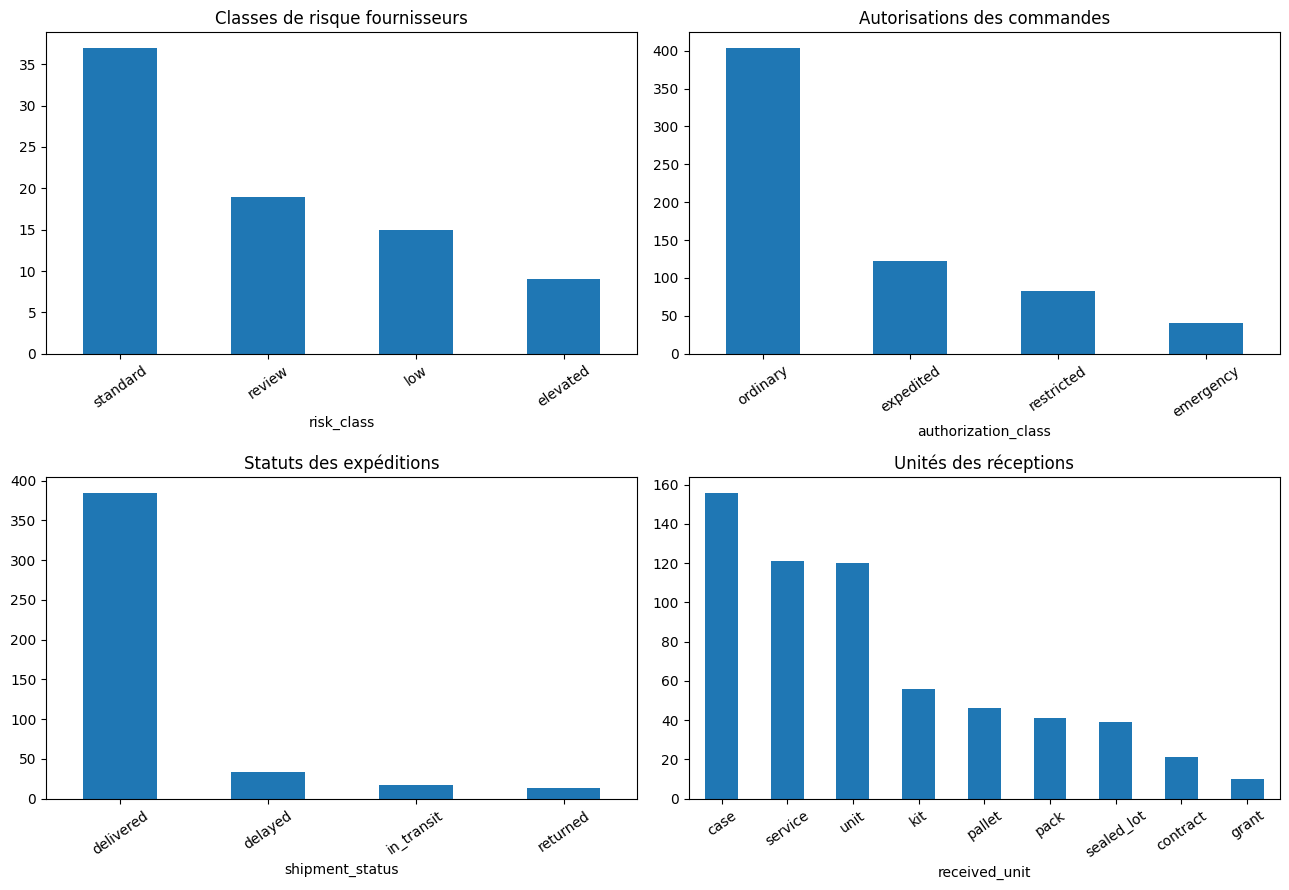

Commandes en sealed_lot


,count,mean,std,min,25%,50%,75%,max
ordered_quantity,42.0,8.4,4.48,1.0,5.0,7.5,11.0,18.0


Réceptions en sealed_lot


,count,mean,std,min,25%,50%,75%,max
received_quantity,39.0,8.32,4.59,1.0,4.69,8.0,11.0,18.0


Expéditions en sealed_lot


,count,mean,std,min,25%,50%,75%,max
declared_quantity,52.0,6.54,4.38,1.0,3.0,6.0,8.0,18.0


Spearman pour les stocks en sealed_lot :


,opening_stock,received_quantity,outgoing_quantity,documented_internal_use,documented_waste,closing_stock
opening_stock,1.00,0.05,-0.06,0.80,0.52,0.76
received_quantity,0.05,1.00,-0.00,0.27,0.11,0.27
outgoing_quantity,-0.06,-0.00,1.00,-0.23,-0.10,-0.31
documented_internal_use,0.80,0.27,-0.23,1.00,0.50,0.77
documented_waste,0.52,0.11,-0.10,0.50,1.00,0.47
closing_stock,0.76,0.27,-0.31,0.77,0.47,1.00


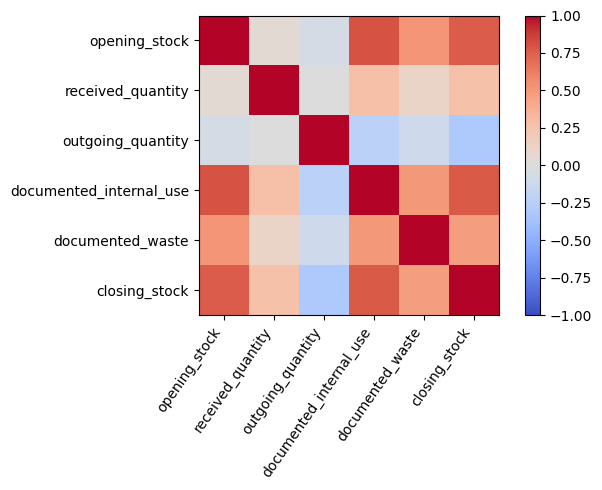

In [5]:
fig,ax=plt.subplots(2,2,figsize=(13,9))
bp.risk_class.value_counts().plot.bar(ax=ax[0,0],title='Classes de risque fournisseurs')
po.authorization_class.value_counts().plot.bar(ax=ax[0,1],title='Autorisations des commandes')
sh.shipment_status.value_counts().plot.bar(ax=ax[1,0],title='Statuts des expéditions')
gr.received_unit.value_counts().plot.bar(ax=ax[1,1],title='Unités des réceptions')
for a in ax.flat:a.tick_params(axis='x',rotation=35)
plt.tight_layout();(ROOT/'figures').mkdir(exist_ok=True);plt.savefig(ROOT/'figures/cours1_distributions_7.png',dpi=130);plt.show()
for title,d,col,unit in [('Commandes',po,'ordered_quantity','sealed_lot'),('Réceptions',gr,'received_quantity','sealed_lot'),('Expéditions',sh,'declared_quantity','sealed_lot')]:
 x=d.loc[d[[c for c in d if c in ['ordered_unit','received_unit','declared_unit']][0]].eq(unit),col]
 print(title,'en',unit);display(x.describe().to_frame().T.round(2))
sm=mo.loc[mo.unit.eq('sealed_lot'),['opening_stock','received_quantity','outgoing_quantity','documented_internal_use','documented_waste','closing_stock']].dropna()
if len(sm)>2:
 print('Spearman pour les stocks en sealed_lot :');display(sm.corr('spearman').round(2))
 plt.figure(figsize=(7,5));plt.imshow(sm.corr('spearman'),vmin=-1,vmax=1,cmap='coolwarm');plt.xticks(range(len(sm.columns)),sm.columns,rotation=55,ha='right');plt.yticks(range(len(sm.columns)),sm.columns);plt.colorbar();plt.tight_layout();plt.savefig(ROOT/'figures/cours1_correlations_7.png',dpi=130);plt.show()


In [6]:
display(Markdown(f"""### Synthèse du cours 1
- **{len(raw)} tables originales** ; **{int(audit.removed_duplicates.sum())} doublons stricts supprimés**.
- **{len(po)} lignes de commande** et **{len(sh)} jambes d'expédition** sont maintenant intégrées.
- **{int(rc_check.found_po.isna().sum())} réceptions** ne retrouvent pas la ligne de commande exacte (à auditer).
- Les colonnes d'identification ne sont ni remplacées ni inventées. `data/part1_clean/` est prêt pour l'étape 2."""))


### Synthèse du cours 1
- **7 tables originales** ; **7 doublons stricts supprimés**.
- **650 lignes de commande** et **450 jambes d'expédition** sont maintenant intégrées.
- **0 réceptions** ne retrouvent pas la ligne de commande exacte (à auditer).
- Les colonnes d'identification ne sont ni remplacées ni inventées. `data/part1_clean/` est prêt pour l'étape 2.